###**Evaluation OF SegformerB0**

### **Training Curves**

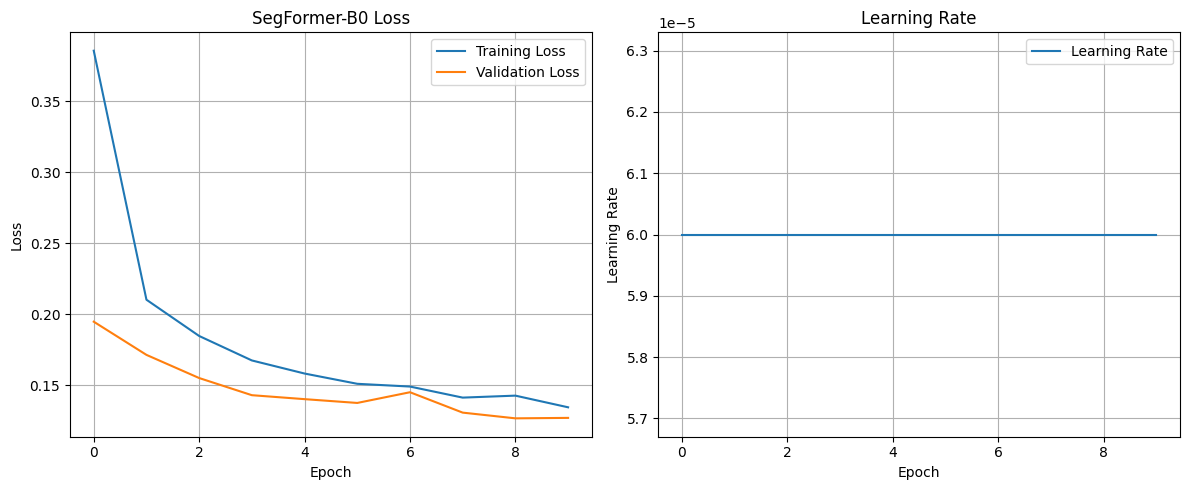

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("SegFormer-B0 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)


plt.subplot(1, 2, 2)

plt.plot(
    history.history["learning_rate"],
    label="Learning Rate"
) if "learning_rate" in history.history else None

plt.title("Learning Rate")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Evaluation — Validation Set**

In [ ]:
confusion_matrix = np.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=np.int64
)

for batch_images, batch_masks in val_ds:

    logits = segformer_model(
        batch_images,
        training=False
    )

    # Ensure predictions have the same spatial size as masks
    if logits.shape[1:3] != batch_masks.shape[1:3]:

        logits = tf.image.resize(
            logits,
            size=tf.shape(batch_masks)[1:3],
            method="bilinear"
        )

    predicted_masks = tf.argmax(
        logits,
        axis=-1,
        output_type=tf.int32
    )

    true_masks = tf.cast(batch_masks, tf.int32)

    if true_masks.shape.rank == 4:
        true_masks = tf.squeeze(true_masks, axis=-1)

    batch_cm = tf.math.confusion_matrix(
        tf.reshape(true_masks, [-1]),
        tf.reshape(predicted_masks, [-1]),
        num_classes=NUM_CLASSES
    )

    confusion_matrix += batch_cm.numpy()


print("Validation Confusion Matrix:")
print(confusion_matrix)

Validation Confusion Matrix:
[[242288441    469825   7587284    618872   1104569]
 [   720377   3067629     17884        18     37209]
 [  6514116      1257 125911075    267864     65272]
 [   856903      1225    126162  23888034       364]
 [  1463555     47539    490425      8346   4400443]]


In [ ]:
epsilon = 1e-7

TP = np.diag(confusion_matrix).astype(np.float64)

FP = (
    confusion_matrix.sum(axis=0) - TP
).astype(np.float64)

FN = (
    confusion_matrix.sum(axis=1) - TP
).astype(np.float64)

IoU = TP / (TP + FP + FN + epsilon)

Dice = (
    2 * TP
) / (
    2 * TP + FP + FN + epsilon
)

Precision = TP / (TP + FP + epsilon)

Recall = TP / (TP + FN + epsilon)

Pixel_Accuracy = TP.sum() / (
    confusion_matrix.sum() + epsilon
)

Mean_IoU = np.mean(IoU)

Foreground_Mean_IoU = np.mean(IoU[1:])

Mean_Dice = np.mean(Dice)

Foreground_Mean_Dice = np.mean(Dice[1:])


results_df = pd.DataFrame({

    "Class": CLASS_NAMES,

    "IoU": IoU,

    "Dice": Dice,

    "Precision": Precision,

    "Recall": Recall

})

print("\nPer-Class Evaluation Results:")
display(results_df.round(4))

print("\nOverall Evaluation:")

print("Mean IoU:", round(Mean_IoU, 4))

print(
    "Foreground Mean IoU:",
    round(Foreground_Mean_IoU, 4)
)

print("Mean Dice:", round(Mean_Dice, 4))

print(
    "Foreground Mean Dice:",
    round(Foreground_Mean_Dice, 4)
)

print("Pixel Accuracy:", round(Pixel_Accuracy, 4))


Per-Class Evaluation Results:


,Class,IoU,Dice,Precision,Recall
0,Background,0.9261,0.9616,0.9621,0.9612
1,Buildings,0.7031,0.8257,0.8551,0.7982
2,Woodlands,0.8931,0.9435,0.9387,0.9484
3,Water,0.9271,0.9621,0.9639,0.9604
4,Roads,0.5777,0.7323,0.7847,0.6865



Overall Evaluation:
Mean IoU: 0.8054
Foreground Mean IoU: 0.7752
Mean Dice: 0.8851
Foreground Mean Dice: 0.8659
Pixel Accuracy: 0.9514


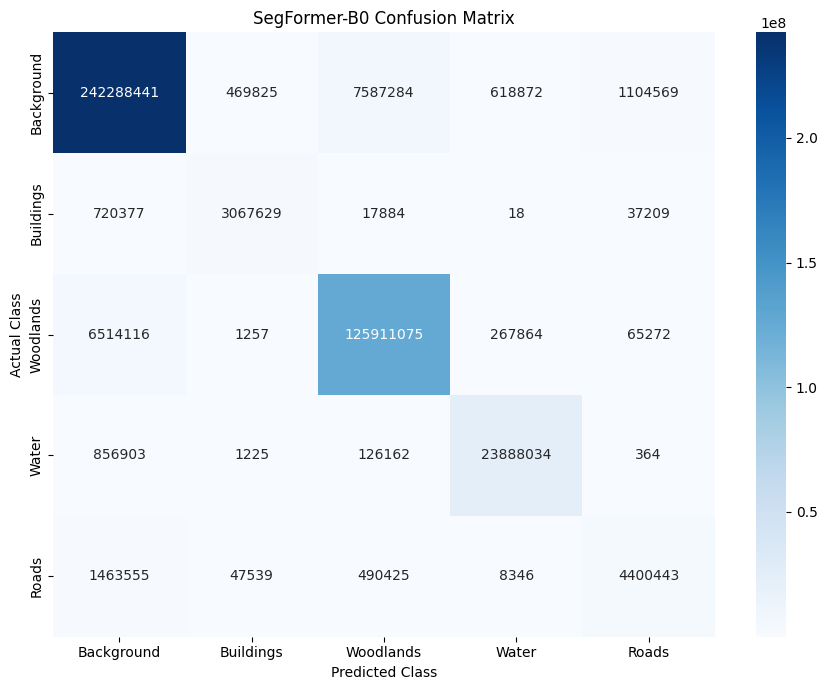

In [ ]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("SegFormer-B0 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

## **Error analysis of SegFormer-B0**

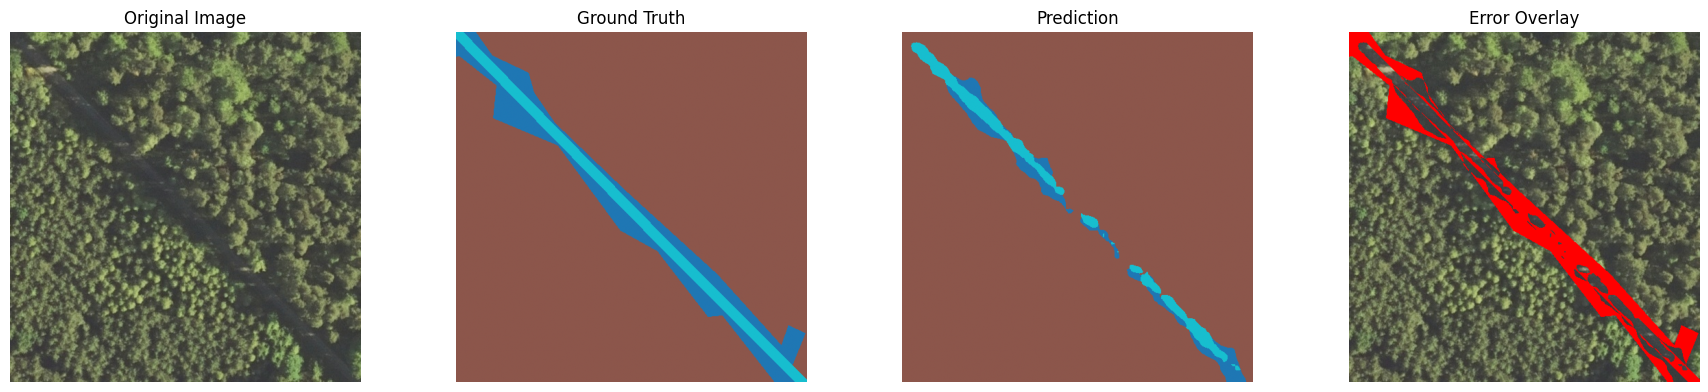

Example 1 - Error Percentage: 7.35 %


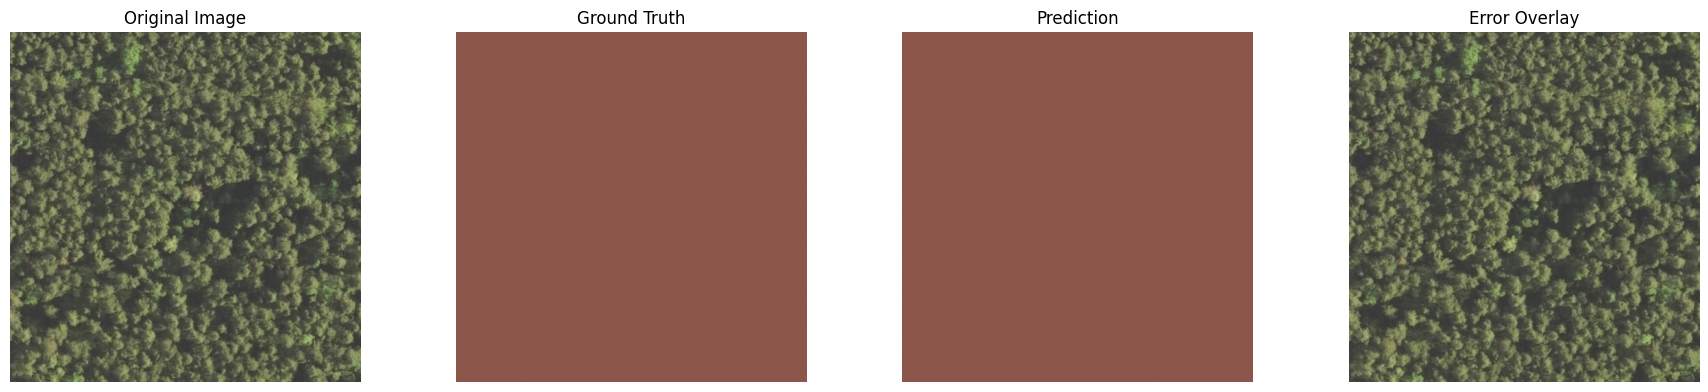

Example 2 - Error Percentage: 0.0 %


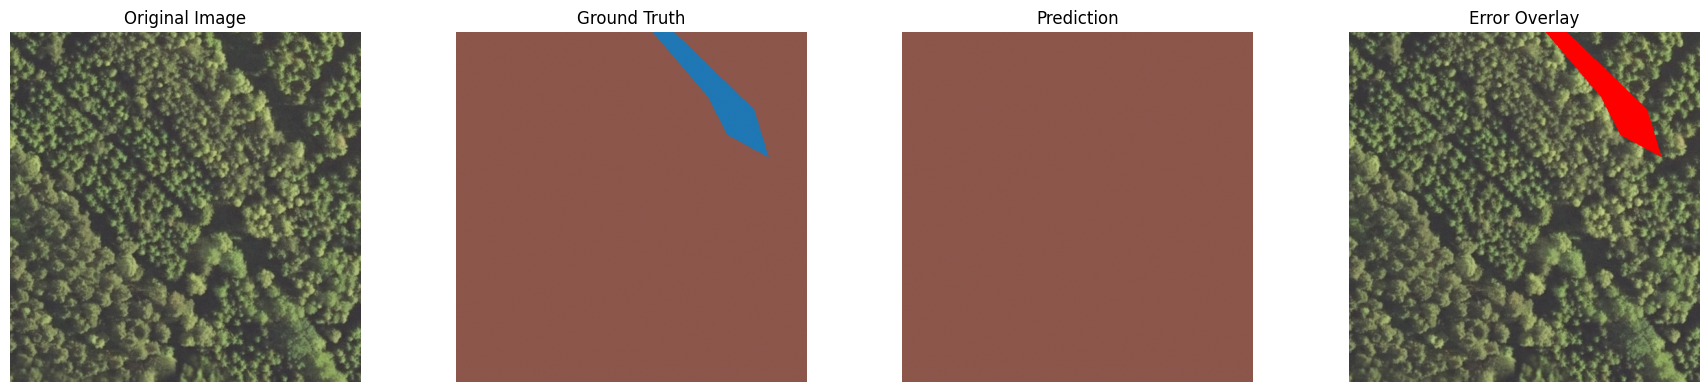

Example 3 - Error Percentage: 2.92 %


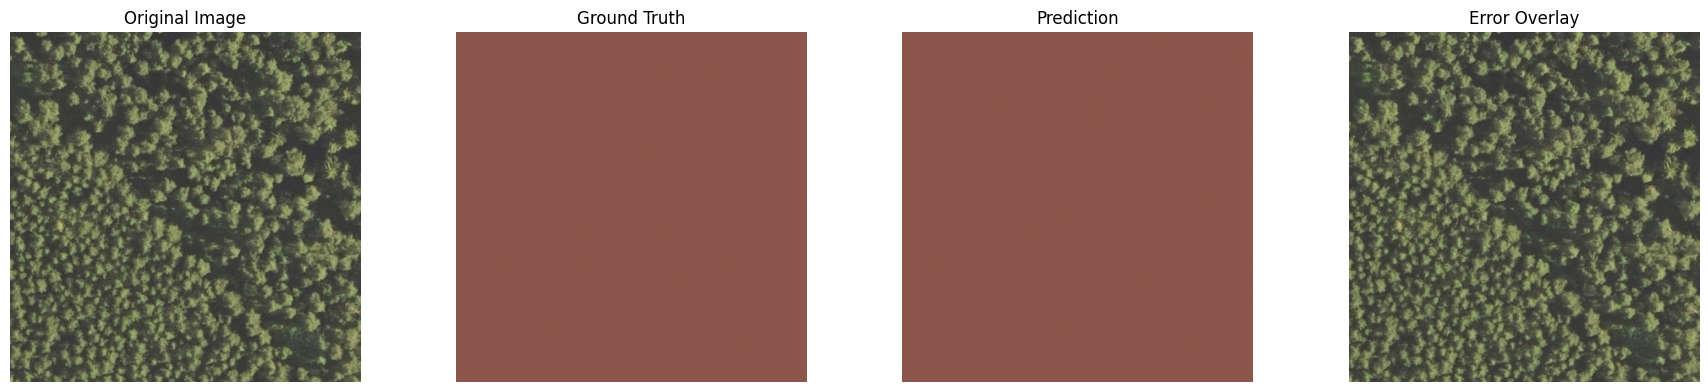

Example 4 - Error Percentage: 0.0 %


In [ ]:
batch_images, batch_masks = next(iter(val_ds))

batch_logits = segformer_model(
    batch_images,
    training=False
)

batch_predictions = tf.argmax(
    batch_logits,
    axis=-1,
    output_type=tf.int32
)

if batch_masks.shape.rank == 4:
    batch_masks = tf.squeeze(batch_masks, axis=-1)


# ImageNet normalization values
mean = np.array([0.485, 0.456, 0.406])

std = np.array([0.229, 0.224, 0.225])


num_examples = min(4, batch_images.shape[0])

for i in range(num_examples):

    image = batch_images[i].numpy()

    image = image * std + mean

    image = np.clip(image, 0, 1)

    ground_truth = batch_masks[i].numpy()

    prediction = batch_predictions[i].numpy()

    error_mask = prediction != ground_truth

    error_overlay = image.copy()

    error_overlay[error_mask] = [1, 0, 0]


    plt.figure(figsize=(18, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(
        ground_truth,
        cmap="tab10",
        vmin=0,
        vmax=NUM_CLASSES - 1
    )
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(
        prediction,
        cmap="tab10",
        vmin=0,
        vmax=NUM_CLASSES - 1
    )
    plt.title("Prediction")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(error_overlay)
    plt.title("Error Overlay")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print(
        f"Example {i+1} - Error Percentage:",
        round(error_mask.mean() * 100, 2),
        "%"
    )

## **Computational Cost**

In [ ]:
# Save the trained model
MODEL_PATH = "/kaggle/working/segformer_b0_landcover.keras"

segformer_model.save(MODEL_PATH)

# Parameter count
total_parameters = segformer_model.count_params()

# Model size
model_size_mb = (
    os.path.getsize(MODEL_PATH) / (1024 ** 2)
)

# GPU information
try:

    gpu_name = subprocess.check_output(
        [
            "nvidia-smi",
            "--query-gpu=name",
            "--format=csv,noheader"
        ],
        text=True
    ).strip()

except Exception:

    gpu_name = str(gpus)


# Inference time
inference_images, _ = next(iter(val_ds))

# Warm-up
for _ in range(3):

    _ = segformer_model(
        inference_images,
        training=False
    ).numpy()


num_runs = 10

inference_start = time.perf_counter()

for _ in range(num_runs):

    _ = segformer_model(
        inference_images,
        training=False
    ).numpy()

inference_total_time = (
    time.perf_counter() - inference_start
)

average_batch_time = inference_total_time / num_runs

average_image_time = (
    average_batch_time / inference_images.shape[0]
)


print("Computational Cost — SegFormer-B0")

print("GPU:", gpu_name)

print(
    "Training Time:",
    round(training_time / 60, 2),
    "minutes"
)

print("Total Parameters:", total_parameters)

print(
    "Model Size:",
    round(model_size_mb, 2),
    "MB"
)

print(
    "Average Inference Time / Batch:",
    round(average_batch_time, 4),
    "seconds"
)

print(
    "Average Inference Time / Image:",
    round(average_image_time, 4),
    "seconds"
)

Computational Cost — SegFormer-B0
GPU: Tesla T4
Tesla T4
Training Time: 59.8 minutes
Total Parameters: 3715941
Model Size: 43.08 MB
Average Inference Time / Batch: 0.2894 seconds
Average Inference Time / Image: 0.0362 seconds
